# Retail Demand Forecasting — Portfolio Reproducibility Version

**Purpose:** demonstrate an auditable forecasting workflow using a deterministic, category-stratified sample of 50 product-store series from the three M5 categories.

**Important:** run every cell from top to bottom in Kaggle with the M5 Forecasting Accuracy dataset attached. This is a portfolio rebuild, not a claim that results reproduce the thesis manuscript.

**Evaluation:** chronological holdout with rolling one-step-ahead features. The test period can use observed sales from earlier test dates; it is not a fixed-origin multi-step forecast.

**Models:** Random Forest, LightGBM, optional XGBoost, and a lag-7 seasonal-naive baseline.

In [15]:
# Imports and reproducibility settings
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error

RANDOM_STATE = 42
N_PRODUCTS = 50
DATA_PATH = "/kaggle/input/datasets/rahnumaafrin/m5-forecasting-accuracy-1/"
np.random.seed(RANDOM_STATE)

required_files = ["calendar.csv", "sales_train_evaluation.csv", "sell_prices.csv"]
missing_files = [name for name in required_files if not (Path(DATA_PATH) / name).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Dataset files not found under {DATA_PATH}. Missing: {missing_files}. "
        "In Kaggle, attach the M5 Forecasting Accuracy dataset and update DATA_PATH to its input folder."
    )
print("Dataset path verified:", DATA_PATH)


Dataset path verified: /kaggle/input/datasets/rahnumaafrin/m5-forecasting-accuracy-1/


## 1. Load data and select a category-stratified sample
Select up to 50 product-store series from FOODS, HOBBIES, and HOUSEHOLD using a fixed random seed within each category. This makes category-level summaries possible while keeping the sample small enough for a portfolio demonstration.

In [16]:
calendar = pd.read_csv(DATA_PATH + "calendar.csv", usecols=["d", "date", "wm_yr_wk", "month", "year", "wday", "snap_CA", "snap_TX", "snap_WI"])
sales = pd.read_csv(DATA_PATH + "sales_train_evaluation.csv")
prices = pd.read_csv(DATA_PATH + "sell_prices.csv")

# Deterministic category-stratified selection, with up to 50 total product-store series.
rng = np.random.default_rng(RANDOM_STATE)
category_values = sorted(sales["cat_id"].dropna().unique())
base_n, remainder = divmod(N_PRODUCTS, len(category_values))
selected_parts = []
for i, category in enumerate(category_values):
    n_take = base_n + (1 if i < remainder else 0)
    candidates = sales.loc[sales["cat_id"] == category, "id"].drop_duplicates().to_numpy()
    chosen = rng.choice(candidates, size=min(n_take, len(candidates)), replace=False)
    selected_parts.extend(chosen.tolist())
selected_ids = pd.Series(selected_parts)
sales_sample = sales[sales["id"].isin(selected_ids)].copy()
day_cols = [c for c in sales_sample.columns if c.startswith("d_")]
print("Selected product-store series:", sales_sample["id"].nunique())
print("Selected categories:", sales_sample["cat_id"].value_counts().to_dict())
print("Daily observations per series (wide columns):", len(day_cols))
print("Calendar shape:", calendar.shape, "Prices shape:", prices.shape)


Selected product-store series: 50
Selected categories: {'HOBBIES': 17, 'FOODS': 17, 'HOUSEHOLD': 16}
Daily observations per series (wide columns): 1941
Calendar shape: (1969, 9) Prices shape: (6841121, 4)


## 2. Reshape and join calendar information
Keep valid sales observations even when a price is unavailable. Missing prices are flagged and imputed from the training data later rather than dropping those rows. This is important because a missing price does not necessarily mean the sales observation itself is invalid.

In [17]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
df = sales_sample.melt(id_vars=id_cols, value_vars=day_cols, var_name="d", value_name="sales")
df = df.merge(calendar, on="d", how="left", validate="many_to_one")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["id", "date"]).reset_index(drop=True)

df = df.merge(prices[["store_id", "item_id", "wm_yr_wk", "sell_price"]], on=["store_id", "item_id", "wm_yr_wk"], how="left", validate="many_to_one")
df["price_missing"] = df["sell_price"].isna().astype(int)
print("Long data shape:", df.shape)
print("Missing sales:", int(df["sales"].isna().sum()))
print("Missing sell_price:", int(df["sell_price"].isna().sum()), f"({df['sell_price'].isna().mean():.1%})")
display(df.head())


Long data shape: (97050, 18)
Missing sales: 0
Missing sell_price: 21301 (21.9%)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,wday,month,year,snap_CA,snap_TX,snap_WI,sell_price,price_missing
0,FOODS_1_021_CA_3_evaluation,FOODS_1_021,FOODS_1,FOODS,CA_3,CA,d_1,0,2011-01-29,11101,1,1,2011,0,0,0,NaN,1
1,FOODS_1_021_CA_3_evaluation,FOODS_1_021,FOODS_1,FOODS,CA_3,CA,d_2,0,2011-01-30,11101,2,1,2011,0,0,0,NaN,1
2,FOODS_1_021_CA_3_evaluation,FOODS_1_021,FOODS_1,FOODS,CA_3,CA,d_3,0,2011-01-31,11101,3,1,2011,0,0,0,NaN,1
3,FOODS_1_021_CA_3_evaluation,FOODS_1_021,FOODS_1,FOODS,CA_3,CA,d_4,0,2011-02-01,11101,4,2,2011,1,1,0,NaN,1
4,FOODS_1_021_CA_3_evaluation,FOODS_1_021,FOODS_1,FOODS,CA_3,CA,d_5,0,2011-02-02,11101,5,2,2011,1,0,1,NaN,1


## 3. Chronological split and leakage-aware features
A single cutoff date is shared by all selected series. Lag and rolling predictors are computed within each series and use only earlier sales. Test-period features can use earlier observed test-period sales, so this is a rolling one-step-ahead evaluation.

In [18]:
unique_dates = np.sort(df["date"].dropna().unique())
split_idx = int(len(unique_dates) * 0.70)
cutoff_date = pd.Timestamp(unique_dates[split_idx])

grouped_sales = df.groupby("id")["sales"]
df["lag_1"] = grouped_sales.shift(1)
df["lag_7"] = grouped_sales.shift(7)
df["lag_14"] = grouped_sales.shift(14)
df["lag_28"] = grouped_sales.shift(28)
df["rolling_mean_7"] = df.groupby("id")["sales"].transform(lambda s: s.shift(1).rolling(7, min_periods=7).mean())
df["rolling_mean_28"] = df.groupby("id")["sales"].transform(lambda s: s.shift(1).rolling(28, min_periods=28).mean())

feature_cols = ["lag_1", "lag_7", "lag_14", "lag_28", "rolling_mean_7", "rolling_mean_28", "month", "year", "wday", "snap_CA", "snap_TX", "snap_WI", "sell_price", "price_missing"]
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
# Drop only rows lacking the target/date or initial lag history; do not drop rows just because price is missing.
model_df = df.dropna(subset=["sales", "date", "lag_1", "lag_7", "lag_14", "lag_28", "rolling_mean_7", "rolling_mean_28"]).copy()
train = model_df[model_df["date"] < cutoff_date].copy()
test = model_df[model_df["date"] >= cutoff_date].copy()

# Learn imputation values from training data only. price_missing remains as a feature.
medians = train[feature_cols].median(numeric_only=True).fillna(0)
train.loc[:, feature_cols] = train[feature_cols].fillna(medians)
test.loc[:, feature_cols] = test[feature_cols].fillna(medians)
X_train, y_train = train[feature_cols], train["sales"]
X_test, y_test = test[feature_cols], test["sales"]
print("Cutoff date:", cutoff_date.date())
print("Train rows:", len(train), "Test rows:", len(test))
print("Train date range:", train.date.min().date(), "to", train.date.max().date())
print("Test date range:", test.date.min().date(), "to", test.date.max().date())
print("Category counts in selected series:", sales_sample.groupby("cat_id")["id"].nunique().to_dict())
print("Missing price rate before imputation:", f"{model_df['sell_price'].isna().mean():.1%}")


Cutoff date: 2014-10-18
Train rows: 66500 Test rows: 29150
Train date range: 2011-02-26 to 2014-10-17
Test date range: 2014-10-18 to 2016-05-22
Category counts in selected series: {'FOODS': 17, 'HOBBIES': 17, 'HOUSEHOLD': 16}
Missing price rate before imputation: 21.3%


## 4. Fit models and generate genuine test predictions
Predictions below come from fitted estimators. If a library is unavailable, its model is skipped with a message; no synthetic predictions are generated.

In [19]:
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=12, min_samples_leaf=2,
        n_jobs=-1, random_state=RANDOM_STATE
    )
}

try:
    from lightgbm import LGBMRegressor
    models["LightGBM"] = LGBMRegressor(
        n_estimators=400, learning_rate=0.05, num_leaves=31,
        subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, verbosity=-1
    )
except ImportError:
    print("LightGBM unavailable; skipped.")

try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=8,
        subsample=0.8, colsample_bytree=0.8, objective="reg:squarederror",
        n_jobs=-1, random_state=RANDOM_STATE
    )
except ImportError:
    print("XGBoost unavailable; skipped.")

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = np.asarray(model.predict(X_test), dtype=float)
    predictions[name] = np.clip(pred, 0, None)
    print(f"Fitted {name}: {len(pred)} predictions")


Fitted Random Forest: 29150 predictions
Fitted LightGBM: 29150 predictions
Fitted XGBoost: 29150 predictions


## 5. Baseline and metrics
The lag-7 baseline predicts the sales observed seven days earlier. All models are evaluated on the same held-out rows. SMAPE is expressed as a percentage; because zeros are common in M5, interpret it alongside MAE/RMSE/RMSLE rather than in isolation.

In [20]:
predictions["Seasonal Naive (lag 7)"] = np.clip(test["lag_7"].to_numpy(dtype=float), 0, None)

def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return 100 * np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps))

results = []
for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "SMAPE (%)": smape(y_test, pred),
        "RMSLE": mean_squared_log_error(np.clip(y_test, 0, None), np.clip(pred, 0, None)) ** 0.5,
    })
metrics = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(metrics.round(4))


,Model,MAE,RMSE,SMAPE (%),RMSLE
0,Random Forest,0.7881,1.5082,149.9490,0.4782
1,LightGBM,0.7754,1.5146,150.5699,0.4714
2,XGBoost,0.7966,1.5367,150.6044,0.4818
3,Seasonal Naive (lag 7),0.9398,2.1682,74.9930,0.6205


## 6. Category-level results and visualization
Category aggregation is for descriptive comparison. Product-level metrics above are the primary row-aligned model comparison; aggregated category curves can hide item-level errors.

In [21]:
test_results = test[["id", "item_id", "cat_id", "date", "sales"]].copy().reset_index(drop=True)
for name, pred in predictions.items():
    test_results[name] = pred

category_rows = []
for category, group in test_results.groupby("cat_id"):
    for name in predictions:
        category_rows.append({
            "Category": category, "Model": name,
            "MAE": mean_absolute_error(group["sales"], group[name]),
            "RMSE": mean_squared_error(group["sales"], group[name]) ** 0.5,
            "SMAPE (%)": smape(group["sales"], group[name]),
        })
category_metrics = pd.DataFrame(category_rows).sort_values(["Category", "RMSE"])
display(category_metrics.round(4))


,Category,Model,MAE,RMSE,SMAPE (%)
0,FOODS,Random Forest,1.0874,1.9331,123.9368
1,FOODS,LightGBM,1.0705,1.9371,124.9898
2,FOODS,XGBoost,1.1098,1.9393,124.4710
3,FOODS,Seasonal Naive (lag 7),1.3859,2.9386,86.6216
4,HOBBIES,Random Forest,0.6585,1.3611,166.8873
5,HOBBIES,LightGBM,0.6431,1.3779,167.3493
6,HOBBIES,XGBoost,0.6606,1.4083,167.6385
7,HOBBIES,Seasonal Naive (lag 7),0.7154,1.7663,65.9795
9,HOUSEHOLD,LightGBM,0.6023,1.0790,159.9207
8,HOUSEHOLD,Random Forest,0.6077,1.0814,159.5899


Best model by held-out row-level RMSE: Random Forest


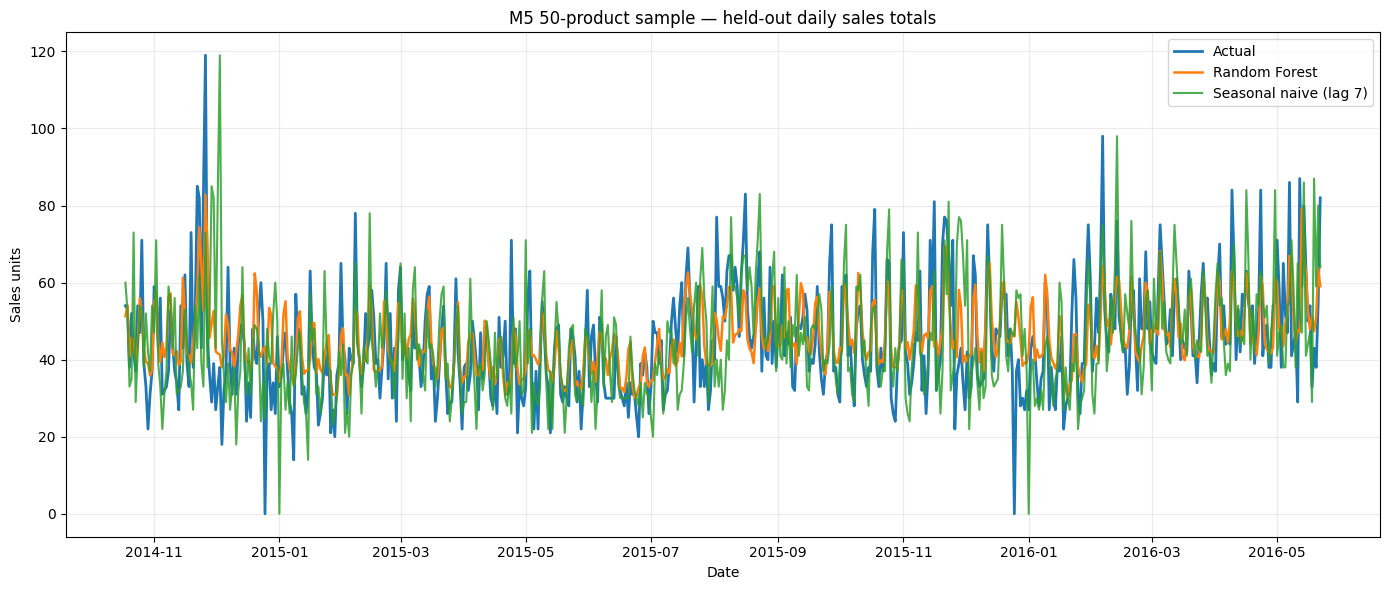

In [22]:
# Plot daily category totals for the best model by overall RMSE and the seasonal-naive baseline.
best_model = metrics.iloc[0]["Model"]
print("Best model by held-out row-level RMSE:", best_model)
plot_df = test_results.groupby("date", as_index=False)[["sales", best_model, "Seasonal Naive (lag 7)"]].sum()
plt.figure(figsize=(14, 6))
plt.plot(plot_df["date"], plot_df["sales"], label="Actual", linewidth=2)
plt.plot(plot_df["date"], plot_df[best_model], label=best_model, linewidth=1.8)
plt.plot(plot_df["date"], plot_df["Seasonal Naive (lag 7)"], label="Seasonal naive (lag 7)", linewidth=1.5, alpha=0.85)
plt.title("M5 50-product sample — held-out daily sales totals")
plt.xlabel("Date"); plt.ylabel("Sales units"); plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()


## 7. Additional experiment: fixed-origin 28-day forecasting

The rolling evaluation above updates features using newly observed actual sales. This separate experiment forecasts the final 28 dates recursively from a single origin: after the origin date, each model uses its own previous predictions to construct later lag and rolling features. No actual sales from the 28-day horizon are used as inputs. Future calendar and scheduled price information are treated as known exogenous inputs.

Models are refit using all eligible feature rows before the forecast origin, with imputation values learned from that training period only. This experiment is distinct from the rolling evaluation; compare the metrics within each experiment rather than treating the two test protocols as interchangeable.


In [23]:
from sklearn.base import clone

HORIZON_DAYS = 28
all_dates = np.sort(df["date"].dropna().unique())
fixed_origin_dates = pd.to_datetime(all_dates[-HORIZON_DAYS:])
origin_date = pd.Timestamp(fixed_origin_dates[0])

fixed_train = model_df.loc[model_df["date"] < origin_date].copy()
fixed_actual = df.loc[df["date"].isin(fixed_origin_dates), ["id", "item_id", "cat_id", "date", "sales"]].copy()
fixed_actual = fixed_actual.sort_values(["date", "id"]).reset_index(drop=True)
fixed_medians = fixed_train[feature_cols].median(numeric_only=True).fillna(0)
X_fixed_train = fixed_train[feature_cols].fillna(fixed_medians)
y_fixed_train = fixed_train["sales"]

# Calendar and prices are known covariates. Only historical sales before the origin
# and model-generated predictions within the horizon are used to build lag features.
history_source = df.loc[df["date"] < origin_date, ["id", "date", "sales"]].sort_values(["id", "date"])
initial_history = {
    series_id: group["sales"].astype(float).tolist()
    for series_id, group in history_source.groupby("id", sort=False)
}
forecast_exog = df.loc[df["date"].isin(fixed_origin_dates)].sort_values(["date", "id"]).copy()


def recursive_fixed_origin_forecast(model=None):
    """Recursive 28-day forecast; model=None gives recursive seasonal naive lag-7."""
    histories = {series_id: values.copy() for series_id, values in initial_history.items()}
    forecast_rows = []
    for forecast_date in fixed_origin_dates:
        day_rows = forecast_exog.loc[forecast_exog["date"] == forecast_date]
        feature_records = []
        row_ids = []
        for _, row in day_rows.iterrows():
            hist = histories[row["id"]]
            if len(hist) < 28:
                raise ValueError(f"Insufficient pre-origin history for {row['id']}")
            feature_records.append({
                "lag_1": hist[-1],
                "lag_7": hist[-7],
                "lag_14": hist[-14],
                "lag_28": hist[-28],
                "rolling_mean_7": float(np.mean(hist[-7:])),
                "rolling_mean_28": float(np.mean(hist[-28:])),
                "month": row["month"],
                "year": row["year"],
                "wday": row["wday"],
                "snap_CA": row["snap_CA"],
                "snap_TX": row["snap_TX"],
                "snap_WI": row["snap_WI"],
                "sell_price": row["sell_price"],
                "price_missing": row["price_missing"],
            })
            row_ids.append(row["id"])
        X_day = pd.DataFrame(feature_records, columns=feature_cols).fillna(fixed_medians)
        if model is None:
            day_pred = X_day["lag_7"].to_numpy(dtype=float)
        else:
            day_pred = np.asarray(model.predict(X_day), dtype=float)
        day_pred = np.clip(day_pred, 0, None)
        for series_id, prediction in zip(row_ids, day_pred):
            histories[series_id].append(float(prediction))
            forecast_rows.append({"id": series_id, "date": forecast_date, "prediction": float(prediction)})
    return pd.DataFrame(forecast_rows)

fixed_predictions = {}
for model_name, model_template in models.items():
    fixed_model = clone(model_template)
    fixed_model.fit(X_fixed_train, y_fixed_train)
    model_forecast = recursive_fixed_origin_forecast(fixed_model).rename(columns={"prediction": model_name})
    fixed_predictions[model_name] = model_forecast
    print(f"Fixed-origin forecast completed: {model_name}")

fixed_predictions["Seasonal Naive (lag 7)"] = recursive_fixed_origin_forecast(None).rename(columns={"prediction": "Seasonal Naive (lag 7)"})
fixed_results = fixed_actual.merge(
    pd.concat([frame.set_index(["id", "date"]) for frame in fixed_predictions.values()], axis=1).reset_index(),
    on=["id", "date"], how="left", validate="one_to_one"
)

fixed_metric_rows = []
for model_name in fixed_predictions:
    y_true = fixed_results["sales"].to_numpy(dtype=float)
    y_pred = fixed_results[model_name].to_numpy(dtype=float)
    fixed_metric_rows.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "SMAPE (%)": smape(y_true, y_pred),
        "RMSLE": mean_squared_log_error(np.clip(y_true, 0, None), np.clip(y_pred, 0, None)) ** 0.5,
        "WAPE (%)": 100 * np.sum(np.abs(y_true - y_pred)) / max(np.sum(y_true), 1e-8),
    })
fixed_metrics = pd.DataFrame(fixed_metric_rows).sort_values("RMSE").reset_index(drop=True)
print("Forecast origin:", (origin_date - pd.Timedelta(days=1)).date())
print("Forecast horizon:", fixed_origin_dates.min().date(), "to", fixed_origin_dates.max().date())
print("Fixed-origin rows:", len(fixed_results))
display(fixed_metrics.round(4))


Fixed-origin forecast completed: Random Forest
Fixed-origin forecast completed: LightGBM
Fixed-origin forecast completed: XGBoost
Forecast origin: 2016-04-24
Forecast horizon: 2016-04-25 to 2016-05-22
Fixed-origin rows: 1400


,Model,MAE,RMSE,SMAPE (%),RMSLE,WAPE (%)
0,LightGBM,0.9837,1.8728,137.4443,0.5349,91.5686
1,Random Forest,0.9442,1.9007,140.6977,0.5219,87.8929
2,XGBoost,0.9275,1.9405,142.5330,0.5175,86.3393
3,Seasonal Naive (lag 7),1.1071,2.2329,90.0876,0.6765,103.0585


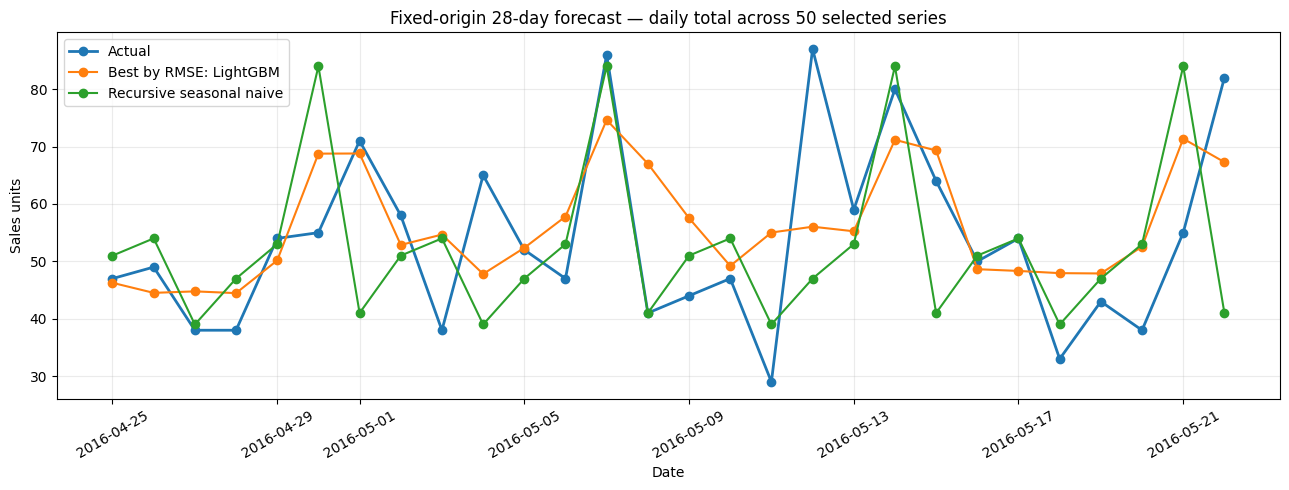

In [24]:
# Visual comparison of total demand across the fixed 28-day horizon.
fixed_daily = fixed_results.groupby("date", as_index=False)[["sales"] + list(fixed_predictions.keys())].sum()
fixed_best_model = fixed_metrics.iloc[0]["Model"]
plt.figure(figsize=(13, 5))
plt.plot(fixed_daily["date"], fixed_daily["sales"], marker="o", label="Actual", linewidth=2)
plt.plot(fixed_daily["date"], fixed_daily[fixed_best_model], marker="o", label=f"Best by RMSE: {fixed_best_model}")
plt.plot(fixed_daily["date"], fixed_daily["Seasonal Naive (lag 7)"], marker="o", label="Recursive seasonal naive")
plt.title("Fixed-origin 28-day forecast — daily total across 50 selected series")
plt.xlabel("Date")
plt.ylabel("Sales units")
plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 8. Interpretation, limitations, and portfolio notes

- The sample is a deterministic, category-stratified subset of up to 50 product-store series, not the full M5 dataset.
- Missing prices are imputed using training-period medians and flagged with `price_missing`; sales targets are retained.
- **Rolling evaluation:** later test-date lag features use actual sales from earlier dates, so it represents rolling one-step-ahead prediction.
- **Fixed-origin evaluation:** the final 28 dates are forecast recursively from one origin; within-horizon lags and rolling means use each model's own predictions. Future calendar and scheduled price data are treated as known.
- The two evaluation protocols answer different questions. Report them separately and do not compare their metric values as if they came from the same test task.
- M5 contains many zero sales and heterogeneous series. Interpret SMAPE carefully and report its exact definition; consider MAE/RMSE/WAPE alongside it.
- This notebook is separate from the thesis results. Do not describe these outputs as thesis results unless the thesis methodology and sample are deliberately aligned and the results are re-verified.
- For a public repository, include the dataset citation, package versions, run instructions, and a concise explanation of the business question. Do not redistribute raw data unless permitted.
